In [1]:
import sys

import matplotlib
import numpy
import pandas
import sklearn

print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__, matplotlib.__version__)

3.12.6 2.3.4 2.3.3 1.7.2 3.10.7


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 3012          
data = pd.read_csv("data/spambase.csv")
feature_names = [c for c in data.columns if c != "spam"]
X, y = data[feature_names].to_numpy(), data["spam"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(X.shape, round(100 * y.mean(), 1), X_train.shape, X_test.shape)

(4204, 57) 39.9 (3153, 57) (1051, 57)


In [3]:
import sys, os
print(sys.executable)

c:\Users\User\Downloads\task-04-ML-course-main (1)\zhumanov_ML_task_4\.zhumanov_ML_task_4\Scripts\python.exe


SEED = 3012

In [ ]:
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=SEED)
bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, oob_score=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=SEED, n_jobs=-1)
lr = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=2000))
bag_lr = BaggingClassifier(lr, n_estimators=50, random_state=SEED)
knn = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), KNeighborsClassifier(n_neighbors=15))
ada = AdaBoostClassifier(n_estimators=400, random_state=SEED)
members = [("lr", lr), ("knn", knn), ("tree", tree)]  

# Part 1

In [5]:
import numpy as np

def oob_mask(sample_indices, n_samples):
    """Boolean mask of the rows that do NOT occur in sample_indices."""
    mask = np.ones(n_samples, dtype=bool)
    idx = np.asarray(sample_indices, dtype=int)
    mask[idx] = False
    return mask

In [6]:
print(oob_mask([0, 2, 2], 5))
print(oob_mask([], 3))
print(oob_mask(np.array([3, 0]), 4))

[False  True False  True  True]
[ True  True  True]
[False  True  True False]


In [7]:
bag.fit(X_train, y_train)
print(len(bag.estimators_), len(bag.estimators_samples_))

100 100


In [8]:
n = len(X_train)

oob_shares = [
    oob_mask(idx, n).mean()
    for idx in bag.estimators_samples_
]
mean_oob_share = np.mean(oob_shares)
mean_in_share = 1 - mean_oob_share

formula_oob = (1 - 1 / n) ** n
formula_in = 1 - formula_oob

print("mean out-of-bag share:", mean_oob_share)
print("mean in-bag share:    ", mean_in_share)
print("formula (1-1/n)^n:    ", formula_oob)
print("formula 1-(1-1/n)^n:  ", formula_in)

mean out-of-bag share: 0.36847446875991124
mean in-bag share:     0.6315255312400887
formula (1-1/n)^n:     0.3678210954587638
formula 1-(1-1/n)^n:   0.6321789045412363


In [9]:
n = len(X_train)
votes = np.zeros((n, 2), dtype=int)

for tree_k, idx in zip(bag.estimators_, bag.estimators_samples_):
    mask = oob_mask(idx, n)
    if mask.any():
        pred = tree_k.predict(X_train[mask])
        rows = np.where(mask)[0]
        votes[rows, pred.astype(int)] += 1

oob_pred = np.argmax(votes, axis=1)   # tie -> class 0
my_oob_acc = (oob_pred == y_train).mean()

print("my OOB accuracy:  ", my_oob_acc)
print("bag.oob_score_:   ", bag.oob_score_)
print("rows with no OOB votes:", (votes.sum(axis=1) == 0).sum())

my OOB accuracy:   0.937836980653346
bag.oob_score_:    0.937836980653346
rows with no OOB votes: 0


In [10]:
from sklearn.model_selection import cross_validate

models = {"tree": tree, "bag": bag, "rf": rf, "lr": lr, "bag_lr": bag_lr}
fold_scores = {}
for name, model in models.items():
    fold_scores[name] = cross_validate(
        model, X_train, y_train, cv=cv, scoring="accuracy"
    )["test_score"]

table = pd.DataFrame(fold_scores, index=[f"fold {i+1}" for i in range(5)]).T
table["mean"] = [s.mean() for s in fold_scores.values()]
table["std"] = [np.std(s) for s in fold_scores.values()]
print(table.round(4))

        fold 1  fold 2  fold 3  fold 4  fold 5    mean     std
tree    0.8970  0.9160  0.8811  0.8778  0.9079  0.8960  0.0148
bag     0.9334  0.9366  0.9303  0.9381  0.9413  0.9359  0.0038
rf      0.9414  0.9461  0.9414  0.9460  0.9571  0.9464  0.0058
lr      0.9350  0.9461  0.9366  0.9286  0.9333  0.9359  0.0058
bag_lr  0.9414  0.9429  0.9319  0.9286  0.9349  0.9359  0.0055


In [11]:
def paired(a, b):
    d = fold_scores[a] - fold_scores[b]
    m, s = d.mean(), np.std(d)
    print(f"{a} - {b}: folds={np.round(d, 4)}  mean={m:.4f}  std={s:.4f}  "
          f"inside spread: {abs(m) <= s}")

paired("bag", "tree")
paired("rf", "tree")
paired("bag_lr", "lr")

bag - tree: folds=[0.0365 0.0206 0.0491 0.0603 0.0333]  mean=0.0400  std=0.0136  inside spread: False
rf - tree: folds=[0.0444 0.0301 0.0602 0.0683 0.0492]  mean=0.0504  std=0.0131  inside spread: False
bag_lr - lr: folds=[ 0.0063 -0.0032 -0.0048  0.      0.0016]  mean=0.0000  std=0.0039  inside spread: True


**(a) Does bagging change cross-validation accuracy?**

For the decision tree, the paired fold differences bag − tree are [0.0365, 0.0206, 0.0491, 0.0603, 0.0333], with mean 0.0400 and std 0.0136. The absolute mean is larger than the std, so the difference is outside the fold spread: bagging improves the tree by about 4 percentage points, and all five folds agree in sign. A single fully grown tree has high variance: it fits the noise of its training sample and changes a lot when the sample changes. Averaging 100 trees trained on different bootstrap samples cancels much of this noise, while the bias stays almost the same.

For logistic regression, the paired differences bag_lr − lr are [0.0063, -0.0032, -0.0048, 0.0000, 0.0016], with mean 0.0000 and std 0.0039. The absolute mean is not larger than the std, so the difference is inside the fold spread, and the signs differ between folds. My data cannot separate bagged logistic regression from plain logistic regression. Logistic regression is a stable, low-variance learner, so there is little variance to average away. Each bootstrap copy also sees only about 63% of the distinct rows, which makes each member slightly weaker, and this roughly cancels the small gain from averaging.

For comparison, rf − tree has mean 0.0504 and std 0.0131, so the forest is also clearly better than the single tree. Random feature selection at each split makes the trees less correlated than in plain bagging, which is why the forest does even better.

In [12]:
import math

rf.fit(X_train, y_train)

oob_rf = rf.oob_score_
cv_mean = fold_scores["rf"].mean()
cv_std = np.std(fold_scores["rf"])

p = rf.score(X_test, y_test)
n_test = len(y_test)
se = math.sqrt(p * (1 - p) / n_test)

print("oob_score_:       ", round(oob_rf, 4))
print("CV mean ± std:    ", round(cv_mean, 4), "±", round(cv_std, 4))
print("test accuracy p:  ", round(p, 4), " SE:", round(se, 4))
print("|oob - cv mean|:  ", round(abs(oob_rf - cv_mean), 4))
print("agree (<= CV std):", abs(oob_rf - cv_mean) <= cv_std)

oob_score_:        0.9486
CV mean ± std:     0.9464 ± 0.0058
test accuracy p:   0.9496  SE: 0.0067
|oob - cv mean|:   0.0022
agree (<= CV std): True


**(b) Is the forest's out-of-bag score a fair stand-in for its cross-validation score?**

The forest's oob_score_ is 0.9486 and its five-fold cross-validation mean is 0.9464 (std 0.0058 over the folds). The absolute difference is 0.0022, which is not larger than the fold std of 0.0058, so by the rule of this task the two numbers agree. Here the out-of-bag score is a fair stand-in for the cross-validation score: it comes from a single fit, uses each training row only through trees that never saw it, and so costs about one fit instead of five.

On the test split the forest has accuracy p = 0.9496 with standard error sqrt(p(1 - p)/n_test) = 0.0067. The test accuracy differs from the out-of-bag score by 0.0010 and from the cross-validation mean by 0.0032, both well inside one standard error. So all three estimates (0.9486, 0.9464, 0.9496) are statistically indistinguishable on this data, and none of them suggests that the forest overfits the training split.

# Part 2

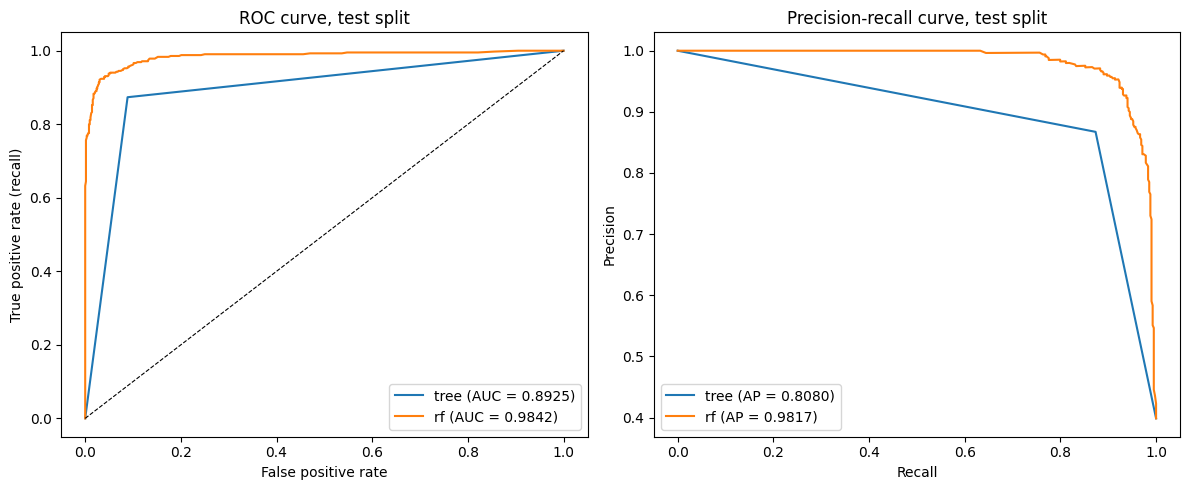

tree AUC: 0.8925 AP: 0.808
rf AUC: 0.9842 AP: 0.9817


In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score)

tree.fit(X_train, y_train)
rf.fit(X_train, y_train)

scores = {
    "tree": tree.predict_proba(X_test)[:, 1],
    "rf": rf.predict_proba(X_test)[:, 1],
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for name, s in scores.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    auc = roc_auc_score(y_test, s)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")

    prec, rec, _ = precision_recall_curve(y_test, s)
    ap = average_precision_score(y_test, s)
    axes[1].plot(rec, prec, label=f"{name} (AP = {ap:.4f})")

axes[0].plot([0, 1], [0, 1], "k--", linewidth=0.8)
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curve, test split")
axes[0].legend(loc="lower right")

axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curve, test split")
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

for name, s in scores.items():
    print(name, "AUC:", round(roc_auc_score(y_test, s), 4),
          "AP:", round(average_precision_score(y_test, s), 4))

In [14]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve

oof = cross_val_predict(rf, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

fpr_oof, tpr_oof, thr_oof = roc_curve(y_train, oof, drop_intermediate=False)

ok = fpr_oof <= 0.01
best_recall = tpr_oof[ok].max()
candidates = ok & (tpr_oof == best_recall)
t = thr_oof[candidates].max()      # largest threshold among those with the best recall

i = np.where(thr_oof == t)[0][0]
print("threshold t:", t)
print("out-of-fold FPR at t:", fpr_oof[i])
print("out-of-fold recall at t:", tpr_oof[i])

threshold t: 0.7866666666666666
out-of-fold FPR at t: 0.00949367088607595
out-of-fold recall at t: 0.7724741447891806


In [15]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score

p_test = rf.predict_proba(X_test)[:, 1]
flagged = (p_test >= t).astype(int)

cm = confusion_matrix(y_test, flagged, labels=[0, 1])
print(pd.DataFrame(cm,
                   index=["true legit (0)", "true spam (1)"],
                   columns=["pred legit (0)", "pred spam (1)"]))

tn, fp, fn, tp = cm.ravel()
print("precision:", round(precision_score(y_test, flagged), 4))
print("recall:   ", round(recall_score(y_test, flagged), 4))
print("FPR:      ", round(fp / (fp + tn), 4))
print(f"legitimate test mails flagged: {fp} out of {fp + tn}")

                pred legit (0)  pred spam (1)
true legit (0)             628              4
true spam (1)               94            325
precision: 0.9878
recall:    0.7757
FPR:       0.0063
legitimate test mails flagged: 4 out of 632


In [16]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf, X_test, y_test, n_repeats=10,
                              random_state=SEED, scoring="accuracy")

top_perm = np.argsort(perm.importances_mean)[::-1][:5]
top_imp = np.argsort(rf.feature_importances_)[::-1][:5]

print("Top 5 permutation importance (test split):")
print(pd.DataFrame({"feature": [feature_names[i] for i in top_perm],
                    "perm_importance": perm.importances_mean[top_perm].round(4),
                    "impurity_importance": rf.feature_importances_[top_perm].round(4)}))

print("\nTop 5 impurity importance (rf.feature_importances_):")
print(pd.DataFrame({"feature": [feature_names[i] for i in top_imp],
                    "impurity_importance": rf.feature_importances_[top_imp].round(4),
                    "perm_importance": perm.importances_mean[top_imp].round(4)}))

Top 5 permutation importance (test split):
                      feature  perm_importance  impurity_importance
0            word_freq_remove           0.0326               0.0942
1            char_freq_exclam           0.0181               0.1183
2  capital_run_length_average           0.0147               0.0663
3                word_freq_hp           0.0132               0.0450
4  capital_run_length_longest           0.0092               0.0495

Top 5 impurity importance (rf.feature_importances_):
                      feature  impurity_importance  perm_importance
0            char_freq_exclam               0.1183           0.0181
1            word_freq_remove               0.0942           0.0326
2            char_freq_dollar               0.0902           0.0083
3              word_freq_free               0.0733           0.0033
4  capital_run_length_average               0.0663           0.0147


**Did the 1% target hold on the test split?**

The threshold t = 0.7867 was chosen on the out-of-fold probabilities of the training split only, where it gave an FPR of 0.0095 (at most 0.01) and a recall of 0.7725. Applied once to the test split, it flagged 4 of the 632 legitimate test mails, so the test FPR is 0.0063 and the 1% target held. Precision is 0.9878 and recall is 0.7757, close to the out-of-fold recall. The count is small, though: one legitimate mail changes the FPR by about 0.0016, so the margin to 1% (about 6 mails) is real but not large, and this single split does not prove that the target would hold on another split. The price of the strict target is that about 22% of the spam gets through.

**One feature that ranks differently in the two importances**

char_freq_dollar is third by impurity importance (0.0902) but its permutation importance is only 0.0083. Impurity importance is computed on the training data while the forest is built: it adds up how much each split on the feature reduces impurity, so a feature that is used in many splits scores high. Permutation importance is computed on the test split after the forest is fitted: it shuffles one column and measures how much the test accuracy drops. The two differ here because other features carry much of the same

# Part 3

In [17]:
import numpy as np
import math

def hard_vote(predictions, weights=None):
    """Weighted majority vote of several models' predicted labels, one label per sample."""
    preds = np.array(predictions, dtype=int)          # copy, shape (n_models, n_samples)
    n_models, n_samples = preds.shape
    if weights is None:
        w = [1] * n_models
    else:
        w = list(weights)
    n_labels = int(preds.max()) + 1 if preds.size > 0 else 1
    result = np.zeros(n_samples, dtype=int)
    for j in range(n_samples):
        counts = [0] * n_labels
        for m in range(n_models):                      # sum in model order
            counts[preds[m, j]] += w[m]
        best = 0
        for label in range(1, n_labels):
            if counts[label] > counts[best]:           # strict ">": a tie goes to the smaller label
                best = label
        result[j] = best
    return result

In [18]:
print(hard_vote([[0, 1, 1], [0, 1, 0], [1, 1, 0]]))
print(hard_vote([[0, 1], [1, 0]]))
print(hard_vote([[0, 1], [1, 0]], weights=[1, 2]))
print(hard_vote([[2, 0], [2, 1], [0, 1]]))

[0 1 0]
[0 0]
[1 0]
[2 1]


In [19]:
from sklearn.base import clone
from sklearn.ensemble import VotingClassifier

fitted = {name: clone(m).fit(X_train, y_train) for name, m in members}
member_preds = np.array([fitted[name].predict(X_test) for name, _ in members])  # (3, n_test)

mine = hard_vote(member_preds)
vc_hard = VotingClassifier(members, voting="hard").fit(X_train, y_train)
sk = vc_hard.predict(X_test)

print("shape:", member_preds.shape)
print("agreement with VotingClassifier:", (mine == sk).mean())

names = [name for name, _ in members]
rows = []
for i in range(3):
    for j in range(i + 1, 3):
        rows.append({"pair": f"{names[i]} vs {names[j]}",
                     "disagreement": round((member_preds[i] != member_preds[j]).mean(), 4)})
print(pd.DataFrame(rows))

shape: (3, 1051)
agreement with VotingClassifier: 1.0
          pair  disagreement
0    lr vs knn        0.0571
1   lr vs tree        0.1123
2  knn vs tree        0.1275


In [20]:
from sklearn.model_selection import cross_validate

cv_models = {
    "lr": lr,
    "knn": knn,
    "tree": tree,
    "hard": VotingClassifier(members, voting="hard"),
    "soft": VotingClassifier(members, voting="soft"),
}
fold3 = {}
for name, model in cv_models.items():
    fold3[name] = cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]

table3 = pd.DataFrame(fold3, index=[f"fold {i+1}" for i in range(5)]).T
table3["mean"] = [s.mean() for s in fold3.values()]
table3["std"] = [np.std(s) for s in fold3.values()]
print(table3.round(4))

best = max(["lr", "knn", "tree"], key=lambda k: fold3[k].mean())
print("best member:", best)

def paired3(a, b):
    d = fold3[a] - fold3[b]
    m, s = d.mean(), np.std(d)
    print(f"{a} - {b}: folds={np.round(d, 4)}  mean={m:.4f}  std={s:.4f}  inside spread: {abs(m) <= s}")

paired3("hard", best)
paired3("soft", best)

      fold 1  fold 2  fold 3  fold 4  fold 5    mean     std
lr    0.9350  0.9461  0.9366  0.9286  0.9333  0.9359  0.0058
knn   0.9350  0.9303  0.8938  0.9286  0.9206  0.9217  0.0147
tree  0.8970  0.9160  0.8811  0.8778  0.9079  0.8960  0.0148
hard  0.9319  0.9445  0.9223  0.9349  0.9365  0.9340  0.0072
soft  0.9382  0.9414  0.9223  0.9365  0.9429  0.9363  0.0073
best member: lr
hard - lr: folds=[-0.0032 -0.0016 -0.0143  0.0063  0.0032]  mean=-0.0019  std=0.0070  inside spread: True
soft - lr: folds=[ 0.0032 -0.0048 -0.0143  0.0079  0.0095]  mean=0.0003  std=0.0088  inside spread: True


**Does voting beat the best member?**

The best member by cross-validation mean is logistic regression (0.9359), ahead of knn (0.9217) and the tree (0.8960).

Hard voting has a mean of 0.9340. The paired fold differences hard − lr are [-0.0032, -0.0016, -0.0143, 0.0063, 0.0032], with mean -0.0019 and std 0.0070. The absolute mean is not larger than the std, so the difference is inside the fold spread. The signs differ between folds, and the mean is slightly negative. My data cannot separate hard voting from logistic regression, and I declare no winner.

Soft voting has a mean of 0.9363. The paired differences soft − lr are [0.0032, -0.0048, -0.0143, 0.0079, 0.0095], with mean 0.0003 and std 0.0088. Again the absolute mean is far below the std, so the difference is inside the fold spread and I declare no winner. Soft voting is not better than the best single member here.

A likely reason is that the ensemble is dominated by one strong member. The tree is clearly weaker (0.8960) and makes more errors than the other two, so it adds noise as often as it corrects them. Logistic regression and knn disagree on only 5.7% of the test rows (see the disagreement

# Part 4

In [22]:
from sklearn.base import clone
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict

Z_oof = np.column_stack([
    cross_val_predict(m, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    for _, m in members
])
meta_oof = LogisticRegression().fit(Z_oof, y_train)

Z_test = np.column_stack([
    clone(m).fit(X_train, y_train).predict_proba(X_test)[:, 1]
    for _, m in members
])
my_pred = meta_oof.predict(Z_test)
my_acc = (my_pred == y_test).mean()

stack = StackingClassifier(members, LogisticRegression(), cv=cv).fit(X_train, y_train)
sk_pred = stack.predict(X_test)
sk_acc = stack.score(X_test, y_test)

print("my coef:   ", meta_oof.coef_.ravel())
print("sk coef:   ", stack.final_estimator_.coef_.ravel())
print("max |coef difference|:", np.abs(meta_oof.coef_ - stack.final_estimator_.coef_).max())
print("test predictions identical:", np.array_equal(my_pred, sk_pred))
print("my test accuracy:", round(my_acc, 4), " sklearn:", round(sk_acc, 4))

my coef:    [4.22046835 2.68004066 1.1905411 ]
sk coef:    [4.22046835 2.68004066 1.1905411 ]
max |coef difference|: 0.0
test predictions identical: True
my test accuracy: 0.9286  sklearn: 0.9286


In [23]:
Z_naive = np.column_stack([
    clone(m).fit(X_train, y_train).predict_proba(X_train)[:, 1]
    for _, m in members
])
meta_naive = LogisticRegression().fit(Z_naive, y_train)

coef_table = pd.DataFrame({
    "naive": meta_naive.coef_.ravel(),
    "out-of-fold": meta_oof.coef_.ravel(),
}, index=[name for name, _ in members])
print(coef_table.round(4))

       naive  out-of-fold
lr    2.0234       4.2205
knn   1.8337       2.6800
tree  8.2592       1.1905


**(a) The tree's weight in the naive and the out-of-fold fit**

The meta-learner gives the tree a weight of 8.2592 in the naive fit and only 1.1905 in the out-of-fold fit, about seven times less. In the naive fit the meta-learner is trained on probabilities that each member produced for the same rows it was fitted on. A fully grown decision tree memorises its training rows, so on them its predicted probability is almost always exactly 0 or 1 and almost always correct. The meta-learner sees a member that never makes mistakes and trusts it heavily, although on new data the tree is the weakest of the three (cross-validation mean 0.8960 against 0.9359 for logistic regression). Logistic regression and knn make some errors even on their own training rows, so the naive fit gives them smaller weights (2.0234 and 1.8337) than the out-of-fold fit (4.2205 and 2.6800). In the out-of-fold fit every probability comes from a member that did not see that row, so the meta-learner sees the true quality of each member on unseen data and shifts weight from

In [24]:
from sklearn.model_selection import cross_validate

fold4 = {
    "stack": cross_validate(
        StackingClassifier(members, LogisticRegression(), cv=cv),
        X_train, y_train, cv=cv, scoring="accuracy")["test_score"],
    "soft": fold3["soft"],
    "lr": fold3["lr"],   # best member from Part 3
}

table4 = pd.DataFrame(fold4, index=[f"fold {i+1}" for i in range(5)]).T
table4["mean"] = [s.mean() for s in fold4.values()]
table4["std"] = [np.std(s) for s in fold4.values()]
print(table4.round(4))

def paired4(a, b):
    d = fold4[a] - fold4[b]
    m, s = d.mean(), np.std(d)
    print(f"{a} - {b}: folds={np.round(d, 4)}  mean={m:.4f}  std={s:.4f}  inside spread: {abs(m) <= s}")

paired4("stack", "lr")
paired4("stack", "soft")

       fold 1  fold 2  fold 3  fold 4  fold 5    mean     std
stack  0.9429  0.9429  0.9334  0.9333  0.9397  0.9385  0.0043
soft   0.9382  0.9414  0.9223  0.9365  0.9429  0.9363  0.0073
lr     0.9350  0.9461  0.9366  0.9286  0.9333  0.9359  0.0058
stack - lr: folds=[ 0.0079 -0.0032 -0.0032  0.0048  0.0063]  mean=0.0025  std=0.0048  inside spread: True
stack - soft: folds=[ 0.0048  0.0016  0.0111 -0.0032 -0.0032]  mean=0.0022  std=0.0054  inside spread: True


**(b) Does stacking beat the best member, and does it beat soft voting?**

The best member from Part 3 is logistic regression (cross-validation mean 0.9359). Stacking has a mean of 0.9385 (std 0.0043), soft voting 0.9363 (std 0.0073).

The paired fold differences stack − lr are [0.0079, -0.0032, -0.0032, 0.0048, 0.0063], with mean 0.0025 and std 0.0048. The absolute mean is not larger than the std, so the difference is inside the fold spread, and the sign changes between folds. I declare no winner: my data cannot separate stacking from the best member.

The paired differences stack − soft are [0.0048, 0.0016, 0.0111, -0.0032, -0.0032], with mean 0.0022 and std 0.0054. This is also inside the fold spread, so I declare no winner between stacking and soft voting either.

Stacking has the highest mean of the three and the smallest fold std (0.0043), but a gain of about 0.0025 in accuracy is small compared with the fold-to-fold variation, so it does not support choosing stacking over logistic regression or soft voting on this data. A likely reason is the same as in Part 3: one member (logistic regression) is much stronger than the tree and clearly better than knn, so there is little left for a meta-learner to combine.